# Lab 5: Policy-Based RL with A2C on Space Invaders

Oliver Grudzinski

In [1]:
%pip install -q "gymnasium[atari]" opencv-python torch numpy pandas matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


## Setup

In [2]:
#@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@
#In this code we install and fool around with the gymnasium environment
#Jeremy Kedziora
#17 Nov 2025
#@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@

#In order to set up the kernel used in this notebook I created a virtual env by running the following at the command line:
#conda create -n py_Gym python=3.10
#conda activate py_Gym
#pip install ale-py
#pip install autorom[accept-rom-license]
#AutoROM --accept-license
#pip install "gymnasium[atari,accept-rom-license]" --force-reinstall
#pip install torch
#conda install matplotlib
#conda install ipykernel
#python -m ipykernel install --user --name=py_Gym --display-name="Python py_Gym"

#documentation for the space invaders environment is here: https://ale.farama.org/environments/space_invaders/

In [3]:
#@@@@@@@@@@@@@@@@@@@@@@@
#import useful libraries
#@@@@@@@@@@@@@@@@@@@@@@@
import gymnasium as gym
#from gymnasium.wrappers import AtariPreprocessing
import numpy as np
import ale_py
import cv2

import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torch.distributions import Categorical

torch.autograd.set_detect_anomaly(True)

In [4]:
import os, time
import pandas as pd
import matplotlib.pyplot as plt

#the starter turns on anomaly detection, which is a debugging mode. It made training about 5x slower on my laptop
#(23 ms vs 5 ms per step) and doesn't change any math, so I turn it off
torch.autograd.set_detect_anomaly(False)
torch.set_num_threads(2)    #fastest setting on my CPU for single screens
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')    #GPU if there is one (Rosie)
print('device:', device)

os.makedirs("results", exist_ok=True)
os.makedirs("figures", exist_ok=True)
os.makedirs("models", exist_ok=True)
np.random.seed(0)
torch.manual_seed(0)

FRAMES = 2_000_000    #training frames per agent (each env step is 4 frames)
TUNE_FRAMES = 500_000    #shorter runs for picking alpha and gamma
N_EVAL = 100    #evaluation episodes

device: cpu


In [5]:
#@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@
#A function to set up the environment with automated preprocessing
#@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@
def make_env(env_name = "ALE/SpaceInvaders-v5"):
    """A function to set up the environment
        Takes:
            env_name -- string, the name of the environment in ALE
        Returns:
            an environment set up with standard DQN atari preprocessing (grayscale 84x84, frame_skip=4)
    """
    env = gym.make(env_name, render_mode="rgb_array",frameskip=1)    #make the environment
    env = gym.wrappers.AtariPreprocessing(
        env,
        screen_size=84,
        grayscale_obs=True,
        frame_skip=4,
        scale_obs=True, #note these could also be normalized in the network
        terminal_on_life_loss=False)    #set up the preprocessing choices
    return env

#@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@
def reward_processing(env_reward,done,truncated):
    if not done and not truncated:
        env_reward += 0.25
    if not done and truncated:
        env_reward += 100
    return env_reward

In [6]:
#@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@
#specify the deep learning model architecture for the actor and critic -- in this example they share input layers
#@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@
class CNNActorCritic(nn.Module):
    def __init__(self, config):
        super().__init__()
        # Classic Atari-style conv net

        #set up the convolutional layers
        self.conv_1 = nn.Conv2d(in_channels = config['input']['input_channels']
                      , out_channels = config['conv_layer_1']['out_channels']
                      , kernel_size = config['conv_layer_1']['kernel_size']
                      , stride = config['conv_layer_1']['stride'])    #specify the first convolutional layer
        with torch.no_grad():    #no need to compute the gradient here
            dummy = torch.zeros(1, config['input']['input_channels'], 84, 84)    #generate a dummy input
            c1 = self.conv_1(dummy)    #push through the first convolutional layer
        self.ln1 = nn.LayerNorm(c1.shape[1:])   #set up the first layer normalization

        self.conv_2 = nn.Conv2d(in_channels = config['conv_layer_1']['out_channels']
                      , out_channels = config['conv_layer_2']['out_channels']
                      , kernel_size = config['conv_layer_2']['kernel_size']
                      , stride = config['conv_layer_2']['stride'])    #specify the second convolutional layer
        with torch.no_grad():    #still no need for gradients
            c2 = self.conv_2(c1)    #push the dummy through the second convolutional layer
        self.ln2 = nn.LayerNorm(c2.shape[1:])    #set up the second layer normalization

        self.conv_3 = nn.Conv2d(in_channels = config['conv_layer_2']['out_channels']
                      , out_channels = config['conv_layer_3']['out_channels']
                      , kernel_size = config['conv_layer_3']['kernel_size']
                      , stride = config['conv_layer_3']['stride'])    #specify the third convolutional layer
        with torch.no_grad():    #and yet still no need for gradients
            c3 = self.conv_3(c2)    #push the dummy through the third convolutional layer
        self.ln3 = nn.LayerNorm(c3.shape[1:])    #set up the fourth layer normalization

        #automatically compute convolutional output size (assuming 84x84 inputs)
        x = torch.zeros(1, config['input']['input_channels'], 84, 84)    #set up a dummy input
        with torch.no_grad():    #no need to compute the gradient here
            x = self.conv_1(x)    #push dummy through convolutional layer 1
            x = self.conv_2(x)    #push dummy through convolutional layer 2
            x = self.conv_3(x)    #push dummy through convolutional layer 3
        conv_out_dim = torch.flatten(x).shape[0]    #pull out the shape of the flattened convolutional layer output -- this is the input for the flattened stuff
        
        #set up the fully connected layers and the output layers for the actor and critic
        self.fc = nn.Linear(conv_out_dim, config['fully_connected_layer_neurons'])    #set up a fully connected layer
        self.actor_output = nn.Linear(config['fully_connected_layer_neurons'], config['n_actions'])    #set up the actor output layer
        self.critic_output = nn.Linear(config['fully_connected_layer_neurons'], 1)    #set up the critic output layer, in this case the state value

    def forward(self, h):
        x = F.relu(self.ln1(self.conv_1(h)))    #push history through convolutional layer 1
        x = F.relu(self.ln2(self.conv_2(x)))    #push first layer output through convolutional layer 2
        x = F.relu(self.ln3(self.conv_3(x)))    #push second layer output through convolutional layer 3
        x = torch.flatten(x)    #flatten
        
        x = F.relu(self.fc(x))    #push flattened output through the fully connected layer
        # logits = self.actor_output(x)    #push fully connected layer output through the actor output layer
        action_probs = F.softmax(self.actor_output(x), dim=-1)
        value = self.critic_output(x).squeeze(-1)    #push fully connected layer output through the critic output layer
        return action_probs, value

## The environment (section 2)

In [7]:
env = make_env(env_name = "ALE/SpaceInvaders-v5")
obs, info = env.reset(seed=0)
print("observation shape:", obs.shape, obs.dtype, "range", obs.min(), "-", obs.max())
print("action space:", env.action_space)
print("actions:", env.unwrapped.get_action_meanings())
print("info:", info)

observation shape: (84, 84) float32 range 0.0 - 0.52156866
action space: Discrete(6)
actions: ['NOOP', 'FIRE', 'RIGHT', 'LEFT', 'RIGHTFIRE', 'LEFTFIRE']
info: {'lives': 3, 'episode_frame_number': 22, 'frame_number': 22, 'seeds': (np.uint32(2968811710), np.uint32(3677149159))}


100 episodes of uniformly random actions. With `terminal_on_life_loss=False` an episode is a full game (3 lives).

random: mean return 145.8, var 7658.9, median 125, min 10, max 390, mean length 504 steps


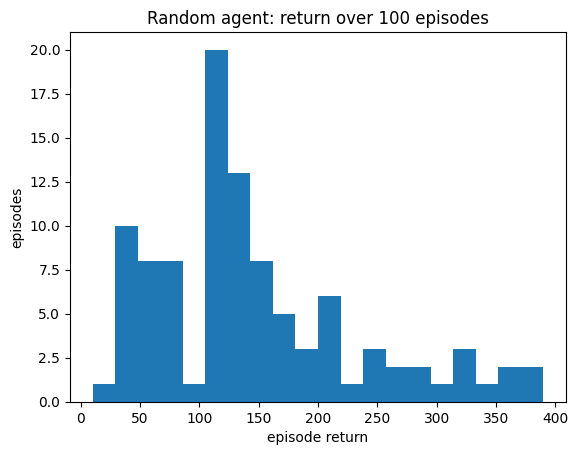

In [8]:
rand_returns, rand_lengths = [], []
for epi in range(100):
    obs, info = env.reset()
    done = truncated = False
    total_reward, steps = 0, 0
    while not (done or truncated):
        obs, reward, done, truncated, info = env.step(env.action_space.sample())
        total_reward += reward
        steps += 1
    rand_returns.append(total_reward)
    rand_lengths.append(steps)
pd.DataFrame({'episode': range(100), 'return': rand_returns, 'steps': rand_lengths}).to_csv("results/random_episodes.csv", index=False)
print(f"random: mean return {np.mean(rand_returns):.1f}, var {np.var(rand_returns):.1f}, median {np.median(rand_returns):.0f}, "
      f"min {min(rand_returns):.0f}, max {max(rand_returns):.0f}, mean length {np.mean(rand_lengths):.0f} steps")

plt.hist(rand_returns, bins=20)
plt.title('Random agent: return over 100 episodes')
plt.xlabel('episode return')
plt.ylabel('episodes')
plt.savefig("figures/random_returns.png", dpi=150)
plt.show()

## A2C agent (section 3)

 During an episode `act`
samples from the actor and keeps log π(a|h), V(h) and the policy entropy with their graphs. After the episode,
`make_objectives_A2C` computes the discounted return G_t for every step, the advantage A_t = G_t - V(h_t)
(detached), and

- policy objective = mean(A_t log π(a_t|h_t)) + β mean(H(π(h_t)))
- value loss = mean((G_t - V(h_t))²)

The loss is -policy objective + value loss. Both heads share the conv layers, so one backward pass and one Adam
step update the actor and critic together.

In [9]:
#@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@
class Agent:
    '''A class to build the agent'''
    
    #@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@
    def __init__(self, config):
        '''Set up the constructor
            Takes -- config
        '''
        self.config = config    #record the config parameters
        self.model = CNNActorCritic(config['CNNconfig']).to(device)    #the shared actor-critic network
        self.optimizer = optim.Adam(self.model.parameters(), lr=config['alpha'])    #one optimizer, so one gradient step updates both heads
        self.reset_buffer()

    #@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@
    def reset_buffer(self):
        '''Clear the per-episode buffer'''
        self.log_probs, self.values, self.entropies, self.rewards = [], [], [], []

    #@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@
    def act(self, h_t):
        '''Sample a ~ pi(.|h_t) and keep log pi(a|h_t), V(h_t) and H(pi(h_t)) (with their graphs) for the update'''
        probs, value = self.model(torch.as_tensor(h_t, device=device))
        dist = Categorical(probs)
        a = dist.sample()
        self.log_probs.append(dist.log_prob(a))
        self.values.append(value)
        self.entropies.append(dist.entropy())
        return a.item()

    #@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@
    def init_history(self,obs,history_length):
        """A state-processing function to start the history at the beginning of an episode
            Takes:
                obs -- a single state
                history_length -- int, the number of states that should be in the history
            Returns:
                the history of stacked single states
        """
        history = []    #A list to store n frames of screen information
        for _ in range(history_length):    #loop over the history length
            # history.append(frame)    #init the history with 4 copies of the first frame
            history.append(obs)    #init the history with 4 copies of the first frame
        return history
    
    #@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@
    def reshape_history(self,history):
        """A state-processing function to put the history in the right shape
            Takes:
                history -- a list of screens
            Returns:
                a reshaped np.array of screen information
        """
        h_t = np.stack(history, axis=0)    #reshape the history to be in the right form for intake into the actor-critic model
        return h_t
    
    #@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@
    def update_history(self,obs,history):
        """A state-processing function to update the history
            Takes:
                obs -- the raw observation
                history -- a list of previous grayscaled, resized screens
            Returns:
                an updated list of grayscaled, resized screens
        """
        history.append(obs)    #add the new frame to the history
        history.pop(0)    #remove the oldest
        return history

    #@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@
    def make_objectives_A2C(self):
        """A function to make the objective for updating the actor and the critic
        Takes:
            buffer information internal to the agent class
        Returns:
            a tuple, first element is the policy objective and the second element is the value loss (MSE)
        """
        G, returns = self.last_value, []    #0 if the episode ended, V(h_T) if it was cut off
        for r in reversed(self.rewards):    #discounted return G_t, computed backwards
            G = r + self.config['gamma'] * G
            returns.append(G)
        returns = torch.tensor(returns[::-1], dtype=torch.float32, device=device)
        values = torch.stack(self.values)
        advantage = (returns - values).detach()    #A_t = G_t - V(h_t), no gradient through the critic here
        policy_objective = (torch.stack(self.log_probs) * advantage).mean() + self.config['beta'] * torch.stack(self.entropies).mean()
        value_loss = F.mse_loss(values, returns)
        return policy_objective, value_loss

### Config

The starter config cell with my values. `history_length` is 4 (the handout), `max_steps` is raised from 200 so
episodes run to the actual game over (random games last ~500 steps), and the starter's `B` is dropped since this
version updates after every episode.

In [10]:
#@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@
#Set up the environment and the agent
#@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@
history_length = 4
CNNconfig = {
    'input':{'input_channels':history_length,'input_size':84}
    ,'n_actions':6
    ,'conv_layer_1':{'out_channels':32,'kernel_size':8,'stride':4}
    ,'conv_layer_2':{'out_channels':64,'kernel_size':4,'stride':2}
    ,'conv_layer_3':{'out_channels':64,'kernel_size':3,'stride':1}
    ,'fully_connected_layer_neurons':512
}    #the config for the actor-critic architecture

Agent_config = {'history_length':history_length    #the number of screens to concatenate into the history
                ,'alpha':0.0001    #the learning rate
                ,'gamma':0.99    #the discount factor
                ,'beta':0.1    #the weight on entropy regularization
                ,'max_steps':5000    #the max steps that an episode runs
                ,'CNNconfig':CNNconfig}

def make_config(**changes):
    '''copy of Agent_config with some entries changed (history_length also changes the CNN input channels)'''
    c = dict(Agent_config, **changes)
    c['CNNconfig'] = dict(CNNconfig, input={'input_channels':c['history_length'],'input_size':84})
    return c

### Training loop

In [11]:
def train(config, n_frames, name):
    torch.manual_seed(0)
    agent = Agent(config)
    env.reset(seed=0)
    log, frames, epi, t0 = [], 0, 0, time.time()
    while frames < n_frames:
        obs, info = env.reset()    #init up the environment
        history = agent.init_history(obs,config['history_length'])    #Init the history
        h_t = agent.reshape_history(history)    #reshape

        steps = 0
        total_reward = 0    #init the total reward accrued in an episode
        stop = False    #init the stopping condition

        agent.reset_buffer()    #reset the n-step buffer
        while not stop:    #run an episode...
            a = agent.act(h_t)    #sample an action from the actor
            obs, reward, done, truncated, info = env.step(a)    #evolve the environment
            agent.rewards.append(reward)
            steps += 1    #increment the number of steps
            if steps >= agent.config['max_steps']:    #if the agent has survived to the end...
                truncated = True    #update the truncation condition
            stop = done or truncated    #update the stopping condition

            history = agent.update_history(obs,history)    #add the new screen and drop the oldest
            h_t = agent.reshape_history(history)    #reshape

            total_reward += reward    #add the reward

            if done or truncated:    #if the episode ended...
                obs, info = env.reset()    #reset the environment

        #bootstrap from V(h_T) only if the episode was cut off rather than ending
        agent.last_value = 0.0 if done else agent.model(torch.as_tensor(h_t, device=device))[1].item()
        policy_objective, value_loss = agent.make_objectives_A2C()    #compute the policy objective and value loss
        loss = -policy_objective + value_loss    #assemble into the objective function (minimize)
        agent.optimizer.zero_grad()    #zero the gradients
        loss.backward()    #backprop
        agent.optimizer.step()    #take a gradient step

        frames += 4 * steps
        epi += 1
        log.append({'episode': epi, 'frames': frames, 'return': total_reward, 'steps': steps,
                    'entropy': torch.stack(agent.entropies).mean().item(), 'value_loss': value_loss.item()})
        if epi % 200 == 0:
            print(f"{name}: episode {epi}, {frames:,} frames, mean return (last 100) "
                  f"{np.mean([l['return'] for l in log[-100:]]):.1f}, {(time.time() - t0) / 60:.0f} min")
    pd.DataFrame(log).to_csv(f"results/train_{name}.csv", index=False)
    torch.save(agent.model.state_dict(), f"models/{name}.pt")
    print(f"{name}: done, {epi} episodes in {(time.time() - t0) / 60:.0f} min")
    return agent, pd.DataFrame(log)

def evaluate(agent, n_episodes, name):
    '''play n_episodes with the trained policy (actions still sampled from pi) and no updates'''
    returns = []
    with torch.no_grad():
        for epi in range(n_episodes):
            obs, info = env.reset()
            history = agent.init_history(obs, agent.config['history_length'])
            h_t = agent.reshape_history(history)
            done = truncated = False
            total_reward = 0
            agent.reset_buffer()
            while not (done or truncated):
                obs, reward, done, truncated, info = env.step(agent.act(h_t))
                history = agent.update_history(obs, history)
                h_t = agent.reshape_history(history)
                total_reward += reward
            returns.append(total_reward)
    agent.reset_buffer()
    pd.DataFrame({'episode': range(n_episodes), 'return': returns}).to_csv(f"results/eval_{name}.csv", index=False)
    return np.array(returns)

def smooth(x, w=100):
    return pd.Series(x).rolling(w, min_periods=1).mean()

### Picking α and γ

I tuned on shorter runs of `TUNE_FRAMES` frames. Every
combination of α in {1e-4, 3e-4} and γ in {0.9, 0.99} gets one short run with β = 0.1, and the main agent uses
whichever had the highest average training return over its last 100 episodes. β gets its own experiment below.

I picked β = 0.1 from three 1M-frame pilot runs (γ = 0.99) I did before writing this notebook. With β = 0.5 and
α = 1e-4 the policy stayed close to uniform (entropy 1.63 over the last 100 episodes, max is ln 6 = 1.79) and averaged
174, about random. With β = 0 the entropy fell to 0.12 by 700k frames. The rewards are 5 to 30 points per alien, so the advantages are in the tens
and β has to be fairly big before the entropy term matters at all.

In [12]:
tune = []
for alpha in [1e-4, 3e-4]:
    for gamma in [0.9, 0.99]:
        _, l = train(make_config(alpha=alpha, gamma=gamma), TUNE_FRAMES, f"tune_a{alpha}_g{gamma}")
        tune.append({'alpha': alpha, 'gamma': gamma, 'episodes': len(l),
                     'mean_return_last_100': l['return'].tail(100).mean(), 'entropy_last_100': l['entropy'].tail(100).mean()})
tune = pd.DataFrame(tune)
tune.to_csv("results/tuning.csv", index=False)
print(tune.round({'mean_return_last_100': 1, 'entropy_last_100': 3}).to_string(index=False))

best = tune.loc[tune['mean_return_last_100'].idxmax()]
Agent_config['alpha'], Agent_config['gamma'] = float(best['alpha']), float(best['gamma'])
print("main agent uses alpha =", Agent_config['alpha'], "gamma =", Agent_config['gamma'], "beta =", Agent_config['beta'])

tune_a0.0001_g0.9: episode 200, 416,608 frames, mean return (last 100) 156.0, 13 min


tune_a0.0001_g0.9: done, 235 episodes in 16 min


tune_a0.0001_g0.99: episode 200, 463,272 frames, mean return (last 100) 228.4, 11 min


tune_a0.0001_g0.99: done, 216 episodes in 11 min


tune_a0.0003_g0.9: episode 200, 420,776 frames, mean return (last 100) 164.3, 11 min


tune_a0.0003_g0.9: done, 239 episodes in 14 min


tune_a0.0003_g0.99: done, 177 episodes in 15 min
 alpha  gamma  episodes  mean_return_last_100  entropy_last_100
0.0001   0.90       235                 171.0             1.679
0.0001   0.99       216                 225.1             0.969
0.0003   0.90       239                 172.6             1.624
0.0003   0.99       177                 298.2             0.076
main agent uses alpha = 0.0003 gamma = 0.99 beta = 0.1


## Training the main agent

main: episode 200, 566,796 frames, mean return (last 100) 289.6, 17 min


main: episode 400, 1,101,260 frames, mean return (last 100) 234.3, 33 min


main: episode 600, 1,583,428 frames, mean return (last 100) 300.5, 47 min


main: done, 764 episodes in 58 min


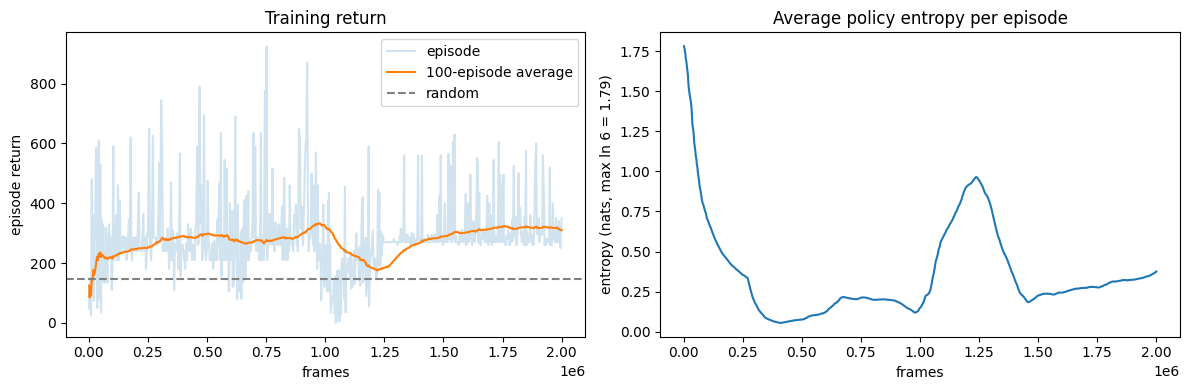

In [13]:
agent, log = train(Agent_config, FRAMES, "main")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(log['frames'], log['return'], alpha=0.2, label='episode')
ax[0].plot(log['frames'], smooth(log['return']), label='100-episode average')
ax[0].axhline(np.mean(rand_returns), color='gray', ls='--', label='random')
ax[0].set_title('Training return')
ax[0].set_xlabel('frames')
ax[0].set_ylabel('episode return')
ax[0].legend()
ax[1].plot(log['frames'], smooth(log['entropy']))
ax[1].set_title('Average policy entropy per episode')
ax[1].set_xlabel('frames')
ax[1].set_ylabel('entropy (nats, max ln 6 = 1.79)')
plt.tight_layout()
plt.savefig("figures/main_training.png", dpi=150)
plt.show()

## Evaluation

N_EVAL episodes with no parameter updates. Actions are still sampled from π, since that's the policy A2C learns.

trained agent: mean return 334.9, variance 11355.7 (std 106.6), median 292, min 170, max 615
random agent:  mean return 145.8, variance 7658.9


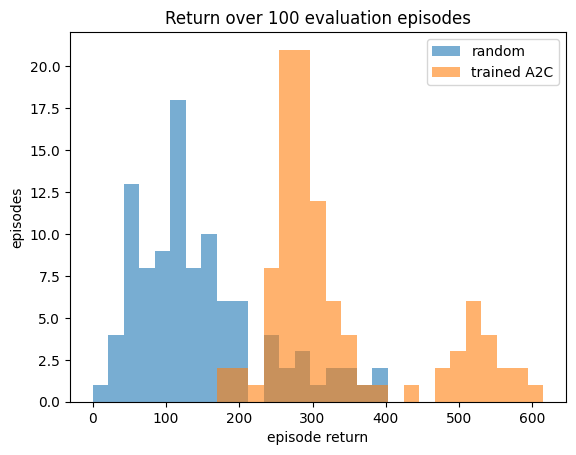

In [14]:
eval_returns = evaluate(agent, N_EVAL, "main")
print(f"trained agent: mean return {eval_returns.mean():.1f}, variance {eval_returns.var():.1f} "
      f"(std {eval_returns.std():.1f}), median {np.median(eval_returns):.0f}, min {eval_returns.min():.0f}, max {eval_returns.max():.0f}")
print(f"random agent:  mean return {np.mean(rand_returns):.1f}, variance {np.var(rand_returns):.1f}")

bins = np.linspace(0, max(eval_returns.max(), max(rand_returns)), 30)
plt.hist(rand_returns, bins=bins, alpha=0.6, label='random')
plt.hist(eval_returns, bins=bins, alpha=0.6, label='trained A2C')
plt.title(f'Return over {N_EVAL} evaluation episodes')
plt.xlabel('episode return')
plt.ylabel('episodes')
plt.legend()
plt.savefig("figures/eval_returns.png", dpi=150)
plt.show()

### What the policy does

One evaluation-style episode, showing the full-color screen at a few points and π(a|h) there, with the action
the agent actually sampled in orange. The last plot is the average of π(a|h) over the whole episode.

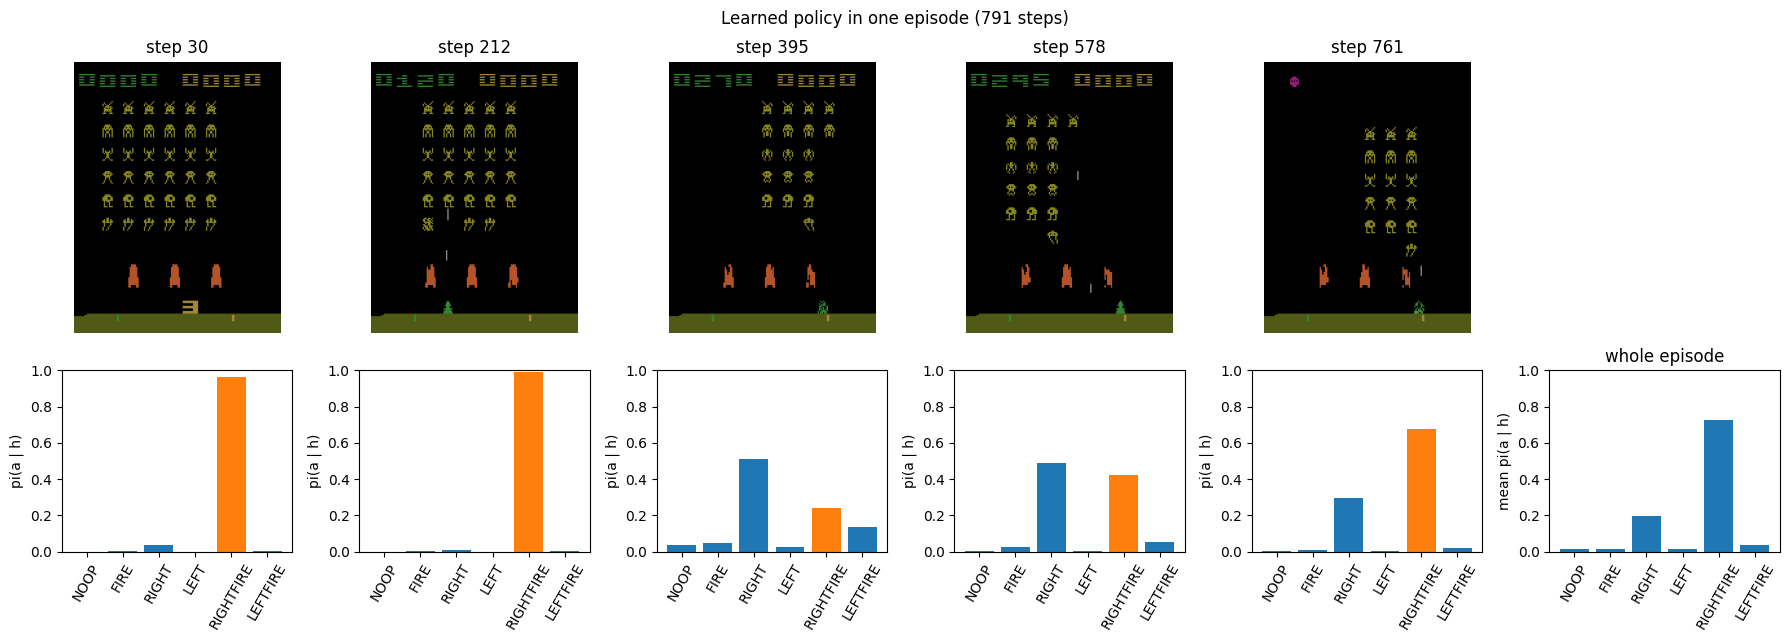

In [15]:
names = env.unwrapped.get_action_meanings()
torch.manual_seed(1)
obs, info = env.reset(seed=1)
history = agent.init_history(obs, agent.config['history_length'])
h_t = agent.reshape_history(history)
frames_rgb, probs_seen, actions, done, truncated = [], [], [], False, False
with torch.no_grad():
    while not (done or truncated):
        probs, _ = agent.model(torch.as_tensor(h_t, device=device))
        frames_rgb.append(env.render())
        probs_seen.append(probs.cpu().numpy())
        actions.append(Categorical(probs).sample().item())
        obs, reward, done, truncated, info = env.step(actions[-1])
        history = agent.update_history(obs, history)
        h_t = agent.reshape_history(history)
probs_seen = np.array(probs_seen)

picks = np.linspace(30, len(frames_rgb) - 30, 5).astype(int)
fig, ax = plt.subplots(2, 6, figsize=(18, 6.5), gridspec_kw={'height_ratios': [3, 2]})
for j, t in enumerate(picks):
    ax[0, j].imshow(frames_rgb[t])
    ax[0, j].set_title(f'step {t}')
    ax[0, j].axis('off')
    ax[1, j].bar(range(6), probs_seen[t], color=['tab:orange' if a == actions[t] else 'tab:blue' for a in range(6)])    #orange = sampled action
    ax[1, j].set_xticks(range(6), names, rotation=60)
    ax[1, j].set_ylim(0, 1)
    ax[1, j].set_ylabel('pi(a | h)')
ax[0, 5].axis('off')
ax[1, 5].bar(range(6), probs_seen.mean(0), label='mean pi(a|h)')
ax[1, 5].set_xticks(range(6), names, rotation=60)
ax[1, 5].set_ylim(0, 1)
ax[1, 5].set_title('whole episode')
ax[1, 5].set_ylabel('mean pi(a | h)')
fig.suptitle(f'Learned policy in one episode ({len(frames_rgb)} steps)')
plt.tight_layout()
plt.savefig("figures/policy_states.png", dpi=150)
plt.show()
pd.DataFrame(probs_seen, columns=names).assign(action=actions).to_csv("results/policy_episode_probs.csv", index_label='step')

## Experiment 1: entropy regularization

Same setup as the main agent, only β changes: no entropy bonus (β = 0), the main agent's β, and a much larger β.
All three train for the same number of frames and get the same evaluation.

beta_0.0: episode 200, 505,520 frames, mean return (last 100) 182.9, 14 min


beta_0.0: episode 400, 1,088,776 frames, mean return (last 100) 294.9, 32 min


beta_0.0: episode 600, 1,697,524 frames, mean return (last 100) 315.5, 48 min


beta_0.0: done, 696 episodes in 57 min


beta_0.5: episode 200, 483,720 frames, mean return (last 100) 217.6, 15 min


beta_0.5: episode 400, 999,352 frames, mean return (last 100) 249.5, 28 min


beta_0.5: episode 600, 1,478,492 frames, mean return (last 100) 187.9, 38 min


beta_0.5: episode 800, 1,937,116 frames, mean return (last 100) 202.7, 53 min


beta_0.5: done, 831 episodes in 54 min


 beta  eval_mean  eval_var  final_train_mean_100  final_entropy_100
  0.0     319.30  16865.51                327.30               0.08
  0.1     334.95  11355.75                309.55               0.38
  0.5     162.30  14046.21                186.10               1.25


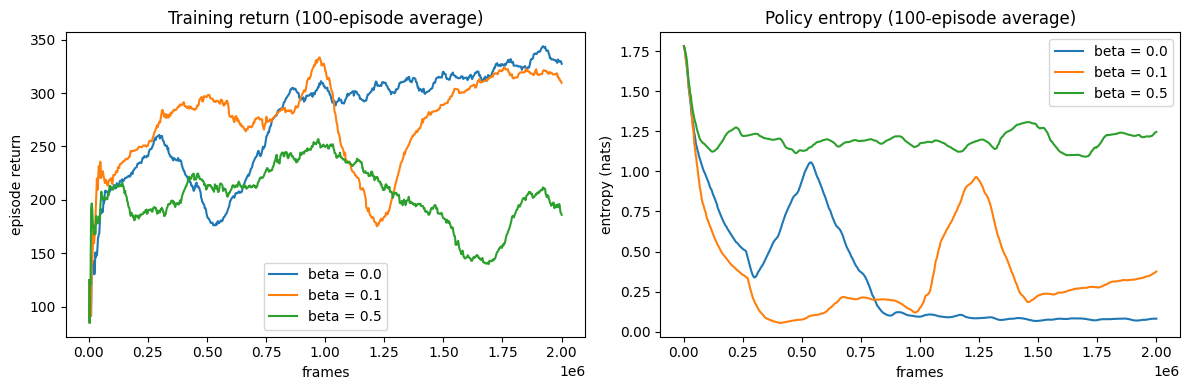

In [16]:
BETAS = [0.0, 0.1, 0.5]
ent_logs, ent_eval = {}, {}
for b in BETAS:
    if b == Agent_config['beta']:
        ent_logs[b], ent_eval[b] = log, eval_returns    #the main agent
        continue
    a_b, ent_logs[b] = train(make_config(beta=b), FRAMES, f"beta_{b}")
    ent_eval[b] = evaluate(a_b, N_EVAL, f"beta_{b}")

rows = [{'beta': b, 'eval_mean': ent_eval[b].mean(), 'eval_var': ent_eval[b].var(),
         'final_train_mean_100': ent_logs[b]['return'].tail(100).mean(),
         'final_entropy_100': ent_logs[b]['entropy'].tail(100).mean()} for b in BETAS]
ent_table = pd.DataFrame(rows)
ent_table.to_csv("results/entropy_experiment.csv", index=False)
print(ent_table.round(2).to_string(index=False))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for b in BETAS:
    ax[0].plot(ent_logs[b]['frames'], smooth(ent_logs[b]['return']), label=f'beta = {b}')
    ax[1].plot(ent_logs[b]['frames'], smooth(ent_logs[b]['entropy']), label=f'beta = {b}')
ax[0].set_title('Training return (100-episode average)')
ax[0].set_xlabel('frames')
ax[0].set_ylabel('episode return')
ax[0].legend()
ax[1].set_title('Policy entropy (100-episode average)')
ax[1].set_xlabel('frames')
ax[1].set_ylabel('entropy (nats)')
ax[1].legend()
plt.tight_layout()
plt.savefig("figures/entropy_experiment.png", dpi=150)
plt.show()

## Experiment 2: frame history

Same as the main agent but with 1 or 2 stacked screens instead of 4. With one screen the agent can't see which way
anything is moving.

history_1: episode 200, 554,672 frames, mean return (last 100) 239.1, 17 min


history_1: episode 400, 1,132,536 frames, mean return (last 100) 245.4, 35 min


history_1: episode 600, 1,694,372 frames, mean return (last 100) 248.3, 44 min


history_1: done, 705 episodes in 53 min


history_2: episode 200, 557,768 frames, mean return (last 100) 254.8, 18 min


history_2: episode 400, 1,032,248 frames, mean return (last 100) 291.2, 32 min


history_2: episode 600, 1,593,692 frames, mean return (last 100) 295.9, 43 min


history_2: done, 744 episodes in 50 min


 history_length  eval_mean  eval_var  final_train_mean_100
              1     228.95   9641.15                284.45
              2     278.00   8430.50                274.50
              4     334.95  11355.75                309.55


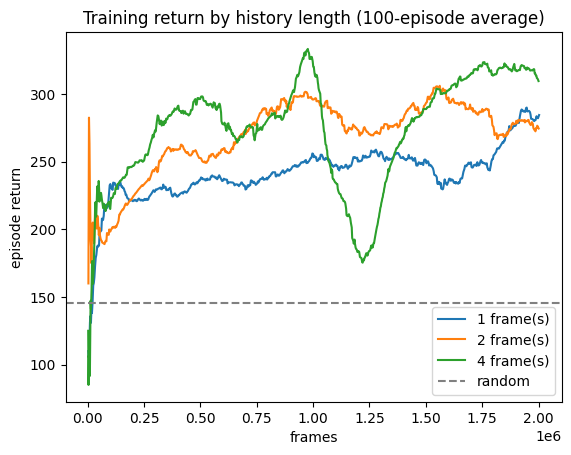

In [17]:
HISTS = [1, 2, 4]
hist_logs, hist_eval = {4: log}, {4: eval_returns}
for n in [1, 2]:
    a_n, hist_logs[n] = train(make_config(history_length=n), FRAMES, f"history_{n}")
    hist_eval[n] = evaluate(a_n, N_EVAL, f"history_{n}")

rows = [{'history_length': n, 'eval_mean': hist_eval[n].mean(), 'eval_var': hist_eval[n].var(),
         'final_train_mean_100': hist_logs[n]['return'].tail(100).mean()} for n in HISTS]
hist_table = pd.DataFrame(rows)
hist_table.to_csv("results/history_experiment.csv", index=False)
print(hist_table.round(2).to_string(index=False))

for n in HISTS:
    plt.plot(hist_logs[n]['frames'], smooth(hist_logs[n]['return']), label=f'{n} frame(s)')
plt.axhline(np.mean(rand_returns), color='gray', ls='--', label='random')
plt.title('Training return by history length (100-episode average)')
plt.xlabel('frames')
plt.ylabel('episode return')
plt.legend()
plt.savefig("figures/history_experiment.png", dpi=150)
plt.show()

In [18]:
env.close()